# Optimisation from scratch Notebook 2
## Gradient stochastique et problème du sac à dos 0/1



In [28]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=6, suppress=True)
RANDOM_SEED = 42
rng = np.random.default_rng(RANDOM_SEED)

# Partie A  Gradient Descent Stochastique

Pour une régression linéaire :

\[
\hat y = X\theta
\]

avec la perte :

\[
J(\theta)=\frac{1}{2n}\|X\theta-y\|^2
\]

SGD utilise une observation à la fois :

\[
\theta_{k+1}=\theta_k-\alpha_k x_i(x_i^T\theta_k-y_i)
\]

Le learning rate peut décroître au cours des mises à jour.

In [29]:
def validate_training_data(X, y):
    X = np.asarray(X, dtype=float)
    y = np.asarray(y, dtype=float)

    if X.ndim != 2:
        raise ValueError("X doit être une matrice 2D.")
    if y.ndim != 1:
        raise ValueError("y doit être un vecteur 1D.")
    if X.shape[0] != y.size:
        raise ValueError("X et y doivent avoir le même nombre d'observations.")
    if X.shape[0] == 0:
        raise ValueError("Le jeu de données ne peut pas être vide.")
    if not np.all(np.isfinite(X)) or not np.all(np.isfinite(y)):
        raise ValueError("X et y doivent contenir uniquement des valeurs finies.")

    return X, y


def mse_half(X, y, theta):
    X, y = validate_training_data(X, y)
    theta = np.asarray(theta, dtype=float)

    if theta.ndim != 1 or theta.size != X.shape[1]:
        raise ValueError("theta doit avoir une dimension égale au nombre de colonnes de X.")

    residuals = X @ theta - y
    return 0.5 * np.mean(residuals ** 2)


def stochastic_gradient_descent_linear_regression(
    X,
    y,
    theta0=None,
    learning_rate=0.01,
    epochs=100,
    decay=0.0,
    shuffle=True,
    random_state=42,
    tol=1e-8,
    patience=5,
):
    """
    SGD from scratch pour une régression linéaire.

    Perte :
        J(theta) = 1/(2n) * ||X theta - y||²

    Gradient individuel :
        g_i = x_i * (x_i.T theta - y_i)
    """
    X, y = validate_training_data(X, y)

    if learning_rate <= 0 or not np.isfinite(learning_rate):
        raise ValueError("learning_rate doit être strictement positif.")
    if not isinstance(epochs, (int, np.integer)) or epochs <= 0:
        raise ValueError("epochs doit être un entier strictement positif.")
    if decay < 0 or not np.isfinite(decay):
        raise ValueError("decay doit être positif ou nul.")
    if tol <= 0 or not np.isfinite(tol):
        raise ValueError("tol doit être strictement positif.")
    if patience <= 0:
        raise ValueError("patience doit être strictement positif.")

    n_samples, n_features = X.shape

    if theta0 is None:
        theta = np.zeros(n_features, dtype=float)
    else:
        theta = np.asarray(theta0, dtype=float).copy()
        if theta.shape != (n_features,):
            raise ValueError("theta0 doit avoir la forme (n_features,).")

    local_rng = np.random.default_rng(random_state)

    history = {
        "loss": [],
        "learning_rate": [],
        "theta": [theta.copy()],
    }

    best_loss = np.inf
    no_improvement = 0
    converged = False
    message = "Nombre maximal d'époques atteint."
    iteration = 0

    for epoch in range(epochs):
        indices = (
            local_rng.permutation(n_samples)
            if shuffle
            else np.arange(n_samples)
        )

        for index in indices:
            iteration += 1

            x_i = X[index]
            y_i = y[index]

            error = x_i @ theta - y_i
            gradient_i = x_i * error

            alpha = learning_rate / (1.0 + decay * (iteration - 1))
            theta -= alpha * gradient_i

            if not np.all(np.isfinite(theta)):
                raise FloatingPointError(
                    "SGD a produit des paramètres non finis. "
                    "Réduisez learning_rate."
                )

        loss = mse_half(X, y, theta)
        current_alpha = learning_rate / (1.0 + decay * (iteration - 1))

        history["loss"].append(float(loss))
        history["learning_rate"].append(float(current_alpha))
        history["theta"].append(theta.copy())

        improvement = abs(best_loss - loss)

        if improvement <= tol:
            no_improvement += 1
        else:
            no_improvement = 0

        best_loss = min(best_loss, loss)

        if no_improvement >= patience:
            converged = True
            message = "Convergence : perte stable."
            break

    return {
        "theta": theta,
        "loss": float(mse_half(X, y, theta)),
        "epochs": epoch + 1,
        "iterations": iteration,
        "converged": converged,
        "message": message,
        "history": history,
    }

## Test du SGD sur des données synthétiques

Nous générons :

\[
y=5+3x_1-2x_2+\epsilon
\]

Le modèle doit retrouver approximativement :

\[
\theta=[5,3,-2]
\]

In [30]:
n_samples = 1000

X_features = rng.normal(size=(n_samples, 2))
noise = rng.normal(scale=0.5, size=n_samples)

y = 5.0 + 3.0 * X_features[:, 0] - 2.0 * X_features[:, 1] + noise

# Colonne de 1 pour le biais
X = np.column_stack([np.ones(n_samples), X_features])

theta_true = np.array([5.0, 3.0, -2.0])

print("X :", X.shape)
print("y :", y.shape)
print("Paramètres théoriques :", theta_true)

X : (1000, 3)
y : (1000,)
Paramètres théoriques : [ 5.  3. -2.]


In [31]:
sgd_result = stochastic_gradient_descent_linear_regression(
    X,
    y,
    theta0=np.zeros(X.shape[1]),
    learning_rate=0.01,
    epochs=100,
    decay=1e-4,
    shuffle=True,
    random_state=42,
    tol=1e-10,
    patience=10,
)

print("Paramètres appris :", sgd_result["theta"])
print("Perte finale :", sgd_result["loss"])
print("Époques :", sgd_result["epochs"])
print("Convergence :", sgd_result["converged"])
print("Erreur par rapport aux paramètres théoriques :",
      np.linalg.norm(sgd_result["theta"] - theta_true))

Paramètres appris : [ 5.012639  3.002069 -2.009166]
Perte finale : 0.1290349706392461
Époques : 100
Convergence : False
Erreur par rapport aux paramètres théoriques : 0.015748827986586833


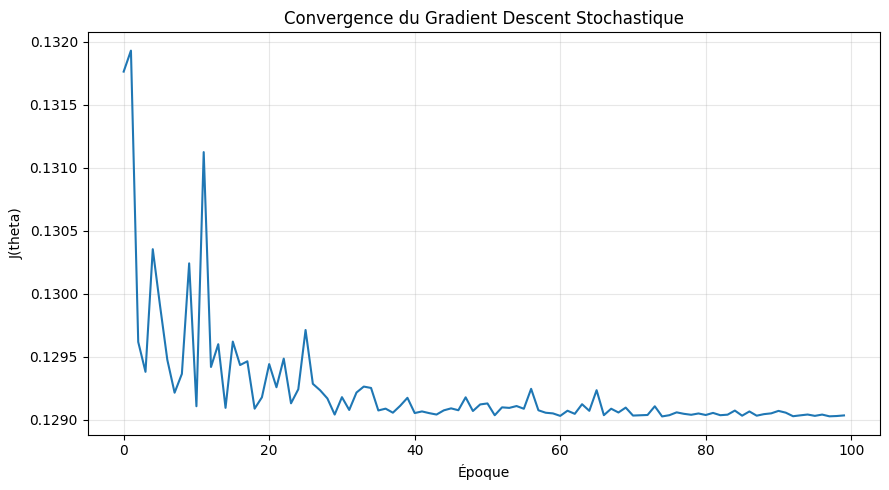

In [32]:
plt.figure(figsize=(9, 5))
plt.plot(sgd_result["history"]["loss"])
plt.xlabel("Époque")
plt.ylabel("J(theta)")
plt.title("Convergence du Gradient Descent Stochastique")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

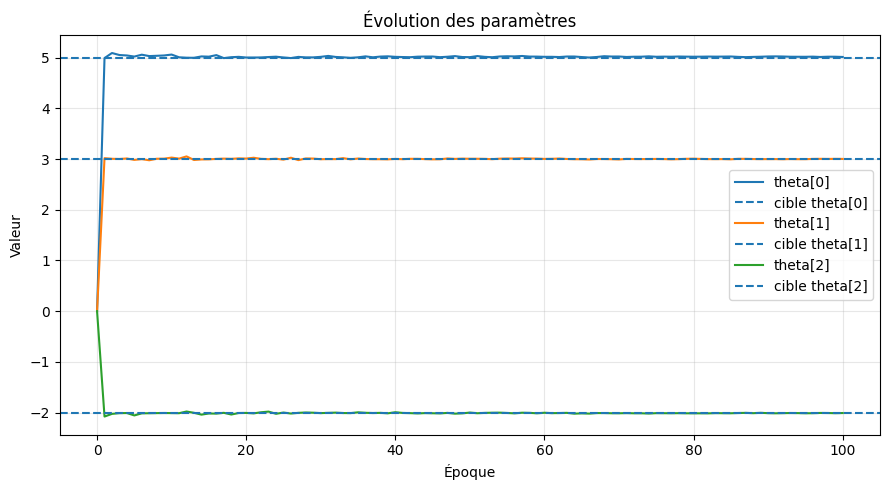

In [33]:
theta_history = np.asarray(sgd_result["history"]["theta"])

plt.figure(figsize=(9, 5))
for j in range(theta_history.shape[1]):
    plt.plot(theta_history[:, j], label=f"theta[{j}]")
    plt.axhline(theta_true[j], linestyle="--", label=f"cible theta[{j}]")

plt.xlabel("Époque")
plt.ylabel("Valeur")
plt.title("Évolution des paramètres")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

## Vérification par solution analytique

Pour les moindres carrés :

\[
X^TX\theta=X^Ty
\]

Nous utilisons `np.linalg.solve` uniquement comme référence numérique.

In [34]:
theta_exact = np.linalg.solve(X.T @ X, X.T @ y)

print("Solution analytique :", theta_exact)
print("Solution SGD        :", sgd_result["theta"])
print("Distance SGD / analytique :",
      np.linalg.norm(sgd_result["theta"] - theta_exact))

Solution analytique : [ 5.016553  3.001446 -2.010307]
Solution SGD        : [ 5.012639  3.002069 -2.009166]
Distance SGD / analytique : 0.0041248182057937975


# Partie B — Problème du sac à dos 0/1


In [41]:
def knapsack_01_dynamic_programming(weights, values, capacity):
    """
    Sac à dos 0/1 exact par programmation dynamique.

    Retourne la valeur optimale, le poids total, les indices
    sélectionnés et la table DP.
    """
    weights = np.asarray(weights)
    values = np.asarray(values, dtype=float)

    if weights.ndim != 1 or values.ndim != 1:
        raise ValueError("weights et values doivent être des vecteurs.")
    if weights.size != values.size:
        raise ValueError("weights et values doivent avoir la même longueur.")
    if weights.size == 0:
        raise ValueError("Il faut au moins un objet.")
    if not np.all(np.isfinite(weights)) or not np.all(np.isfinite(values)):
        raise ValueError("weights et values doivent être finies.")
    if not np.all(weights.astype(int) == weights):
        raise ValueError("Les poids doivent être des entiers.")

    weights = weights.astype(int)

    if np.any(weights <= 0):
        raise ValueError("Les poids doivent être strictement positifs.")
    if not isinstance(capacity, (int, np.integer)) or capacity < 0:
        raise ValueError("capacity doit être un entier positif ou nul.")

    n = weights.size
    dp = np.zeros((n + 1, capacity + 1), dtype=float)

    for i in range(1, n + 1):
        weight = weights[i - 1]
        value = values[i - 1]

        for c in range(capacity + 1):
            dp[i, c] = dp[i - 1, c]

            if weight <= c:
                candidate = dp[i - 1, c - weight] + value
                dp[i, c] = max(dp[i, c], candidate)

    # Reconstruction
    selected_items = []
    c = capacity

    for i in range(n, 0, -1):
        if not np.isclose(dp[i, c], dp[i - 1, c]):
            selected_items.append(i - 1)
            c -= weights[i - 1]

    selected_items.reverse()

    if selected_items:
        total_weight = int(weights[selected_items].sum())
        total_value = float(values[selected_items].sum())
    else:
        total_weight = 0
        total_value = 0.0

    return {
        "value": total_value,
        "weight": total_weight,
        "selected_items": selected_items,
        "dp": dp,
    }

## Exemple

| Objet | Poids | Valeur |
|---:|---:|---:|
| 0 | 2 | 12 |
| 1 | 1 | 10 |
| 2 | 3 | 20 |
| 3 | 2 | 15 |

Capacité du sac : `5`.

In [42]:
weights = np.array([2, 1, 3, 2])
values = np.array([12, 10, 20, 15])
capacity = 5

knapsack_result = knapsack_01_dynamic_programming(
    weights,
    values,
    capacity,
)

print("Objets sélectionnés :", knapsack_result["selected_items"])
print("Poids total :", knapsack_result["weight"])
print("Valeur totale :", knapsack_result["value"])

Objets sélectionnés : [0, 1, 3]
Poids total : 5
Valeur totale : 37.0


In [43]:
selected = knapsack_result["selected_items"]

assert len(selected) == len(set(selected))
assert knapsack_result["weight"] <= capacity

calculated_weight = weights[selected].sum() if selected else 0
calculated_value = values[selected].sum() if selected else 0.0

assert calculated_weight == knapsack_result["weight"]
assert np.isclose(calculated_value, knapsack_result["value"])

print("Toutes les vérifications sont réussies.")

Toutes les vérifications sont réussies.


In [44]:
print("Table DP :")
print(knapsack_result["dp"])

Table DP :
[[ 0.  0.  0.  0.  0.  0.]
 [ 0.  0. 12. 12. 12. 12.]
 [ 0. 10. 12. 22. 22. 22.]
 [ 0. 10. 12. 22. 30. 32.]
 [ 0. 10. 15. 25. 30. 37.]]


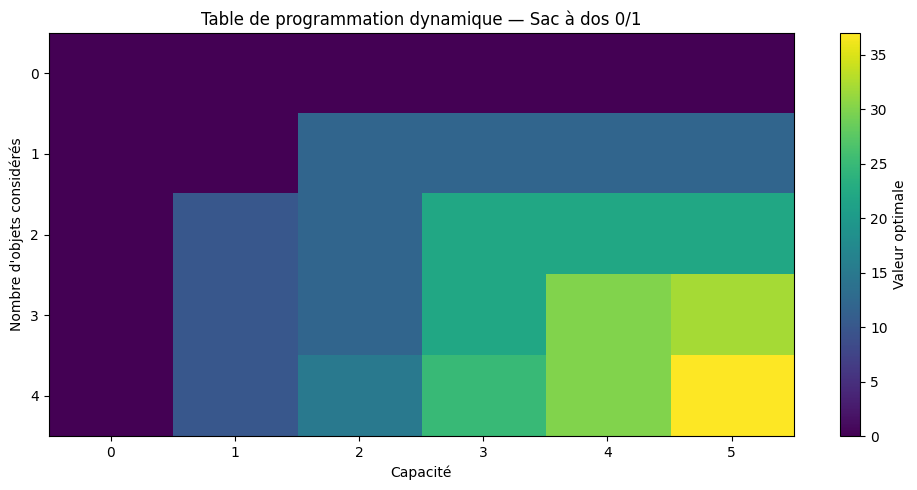

In [45]:
plt.figure(figsize=(10, 5))
plt.imshow(
    knapsack_result["dp"],
    aspect="auto",
    interpolation="nearest"
)
plt.colorbar(label="Valeur optimale")
plt.xlabel("Capacité")
plt.ylabel("Nombre d'objets considérés")
plt.title("Table de programmation dynamique — Sac à dos 0/1")
plt.tight_layout()
plt.show()

## Test sur un problème plus grand

Nous générons 30 objets aléatoires et une capacité de 100.

In [46]:
rng_knapsack = np.random.default_rng(123)

n_items = 30
weights_large = rng_knapsack.integers(1, 20, size=n_items)
values_large = rng_knapsack.integers(5, 100, size=n_items)
capacity_large = 100

large_result = knapsack_01_dynamic_programming(
    weights_large,
    values_large,
    capacity_large
)

print("Nombre d'objets :", n_items)
print("Capacité :", capacity_large)
print("Objets sélectionnés :", large_result["selected_items"])
print("Poids total :", large_result["weight"])
print("Valeur optimale :", large_result["value"])

Nombre d'objets : 30
Capacité : 100
Objets sélectionnés : [0, 1, 3, 4, 5, 6, 7, 8, 9, 10, 15, 20, 23, 25, 27]
Poids total : 99
Valeur optimale : 907.0
